# EDA and cleaning: Mississauga issued building permits

**Objective.** I analyse the City of Mississauga Issued Building Permits database to find growth trends in **non-residential** building permits (Commercial, Industrial, Public). This notebook is my exploratory data analysis (EDA) and cleaning pass so the cleaned CSV is ready for Power BI visualization.

**Research framing.** How has non-residential construction activity changed since 2018, and what does that mean for Invest Mississauga under *Path to Prosperity 2030*?

**Important year rule.** I keep **full calendar years** for 2018–2025. **2026 is incomplete** in the extract (issues through **29 September 2026**). I label 2026 as **2026\*** (YTD) everywhere it appears.

**Scope of this notebook.** I clean and enrich the CSV only. Metric cards, DAX measures, and dashboard storytelling live in Power BI.

**Source file.** `Issued_Building_Permits_7776707631000584226.csv` from [City of Mississauga Open Data – Issued Building Permits](https://data.mississauga.ca/datasets/978ce8c2c5844486b5d768420fa9c72d_0).


## 1. I set up libraries and paths

I import pandas and plotting tools, then point to the downloaded CSV and an `output/` folder for the cleaned file.


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path(".").resolve()
if not (ROOT / "Issued_Building_Permits_7776707631000584226.csv").exists():
    ROOT = Path("..").resolve()

RAW_CSV = ROOT / "Issued_Building_Permits_7776707631000584226.csv"
OUT_DIR = ROOT / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
print("Project root:", ROOT)
print("Raw CSV exists:", RAW_CSV.exists())


Project root: C:\Users\princ\OneDrive\Documents\Other\COM-Assignment\Final_assignment
Raw CSV exists: True


## 2. I load the raw CSV and inspect structure

I read every row from the open-data download and check shape, column names, and a sample of records.


In [2]:
raw = pd.read_csv(RAW_CSV)
print(f"I loaded {len(raw):,} rows and {raw.shape[1]} columns.")
display(pd.DataFrame({"column": raw.columns, "dtype": raw.dtypes.astype(str).values}))
display(raw.head(3))


I loaded 35,042 rows and 26 columns.


,column,dtype
0,OBJECTID,int64
1,BP_NO,object
2,STATUS,object
3,ADDRESS,object
4,UNIT_NO,object
5,DESCRIPTION,object
6,SCOPE,object
7,FILE_TYPE,object
8,BLDG_TYPE,object
9,APP_DETAIL,object


,OBJECTID,BP_NO,STATUS,ADDRESS,UNIT_NO,DESCRIPTION,SCOPE,FILE_TYPE,BLDG_TYPE,APP_DETAIL,APPL_AREA,STOREYS,EST_CON_VALUE,RES_UNITS,DEMO,POSTAL_CODE,BLDG_NO,WARD,ZAREA,LATITUDE,LONGITUDE,APPLICATION_DATE,ISSUE_DATE,COMPLETE_DATE,x,y
0,1,FIRE 17-9125,COMPLETED -ALL INSP SIGNED OFF,3021 ARGENTIA RD,NaN,MODIFY EXISTING KITCHEN FIRE SUPPRESSION FOR K...,ALTERATION TO EXISTING BLDG,COMMERCIAL,COMMERCIAL RETAIL - MULTI-USER,NaN,NaN,NaN,36000.0,NaN,N,L5N 8P7,P,9,55,43.597182,-79.786838,12/19/2017 12:00:00 AM,1/2/2018 12:00:00 AM,5/4/2020 12:00:00 AM,-8.881830e+06,5.403315e+06
1,2,FIRE 17-8818,COMPLETED -ALL INSP SIGNED OFF,90 SKYWAY DR,NaN,INSTALLATION OF (2) MAGLOCKS,ELECTROMAG LOCK DEVICE,INDUSTRIAL,SINGLE TENANT INDUSTRIAL,NaN,NaN,NaN,27000.0,NaN,N,L5W 1N5,NaN,5,44e,43.639025,-79.700800,11/24/2017 12:00:00 AM,1/2/2018 12:00:00 AM,6/5/2018 12:00:00 AM,-8.872252e+06,5.409749e+06
2,3,BP 9ALT 17-8956,COMPLETED -ALL INSP SIGNED OFF,1416 LIVEOAK DR,NaN,INTERIOR ALTERATIONS - LOAD BEARING WALL REMOV...,ALTERATION TO EXISTING BLDG,RESIDENTIAL,DETACHED DWELLING,NaN,NaN,NaN,38000.0,NaN,N,L5E 2X1,NaN,1,05,43.597640,-79.566392,12/6/2017 12:00:00 AM,1/2/2018 12:00:00 AM,5/1/2018 12:00:00 AM,-8.857290e+06,5.403386e+06


## 3. I profile missing values and basic quality

I want a clear picture of nulls before I decide what to keep for Power BI. High null rates on optional fields (storeys, unit number) are expected. Critical fields for this study are FILE_TYPE, SCOPE, EST_CON_VALUE, ADDRESS, ISSUE_DATE, APPLICATION_DATE, LATITUDE, and LONGITUDE.


,null_count,null_pct
STOREYS,32034,91.42
BLDG_NO,29553,84.34
RES_UNITS,28359,80.93
UNIT_NO,25944,74.04
APP_DETAIL,24698,70.48
APPL_AREA,23167,66.11
COMPLETE_DATE,6311,18.01
POSTAL_CODE,28,0.08
ZAREA,20,0.06
SCOPE,1,0.00


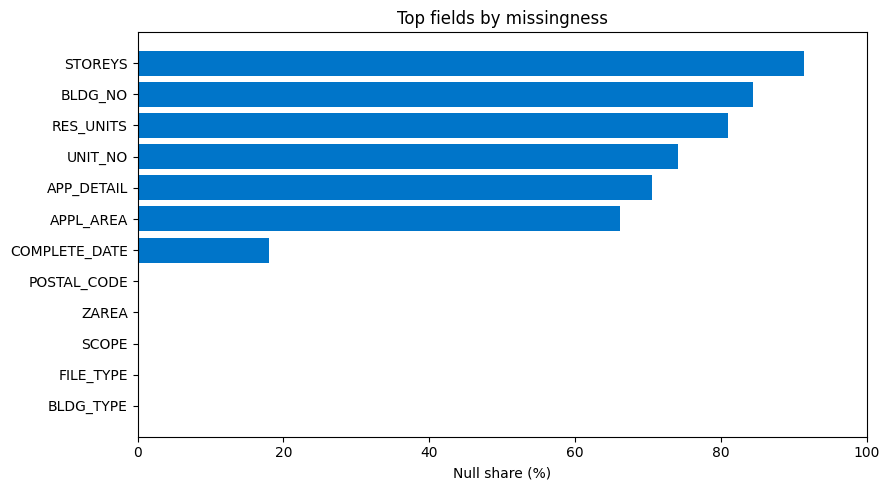

In [3]:
null_tbl = (
    raw.isna()
    .sum()
    .rename("null_count")
    .to_frame()
    .assign(null_pct=lambda d: (100 * d["null_count"] / len(raw)).round(2))
    .sort_values("null_count", ascending=False)
)
display(null_tbl)

fig, ax = plt.subplots(figsize=(9, 5))
top = null_tbl.head(12)
ax.barh(top.index[::-1], top["null_pct"][::-1], color="#0075C9")
ax.set_xlabel("Null share (%)")
ax.set_title("Top fields by missingness")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()


## 4. I parse dates and check the issue-date window

The CSV stores dates as text. I parse APPLICATION_DATE, ISSUE_DATE, and COMPLETE_DATE, then confirm the extract covers 2018 through late September 2026.


ISSUE_DATE range: 2018-01-02 00:00:00 → 2026-09-29 00:00:00
Unparsed ISSUE_DATE: 0
Unparsed APPLICATION_DATE: 0


,permits,note
year,,
2018,3762,Full calendar year in extract
2019,3955,Full calendar year in extract
2020,3518,Full calendar year in extract
2021,3899,Full calendar year in extract
2022,4175,Full calendar year in extract
2023,4329,Full calendar year in extract
2024,4405,Full calendar year in extract
2025,4215,Full calendar year in extract
2026,2784,YTD through 29 Sep (incomplete year)


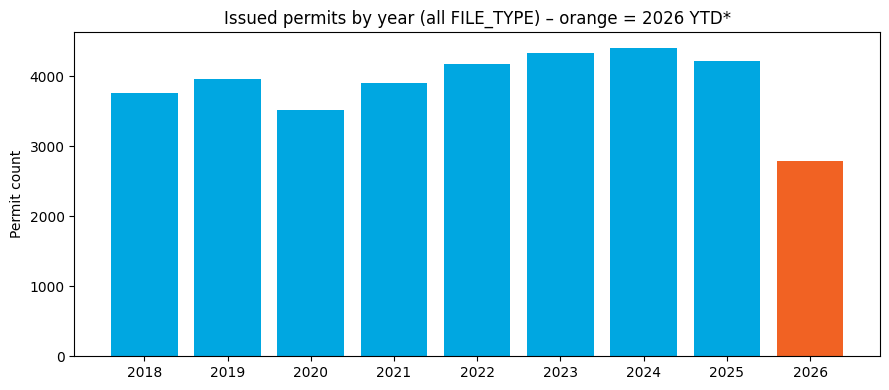

* 2026 is year-to-date through 29 September 2026.


In [4]:
for col in ["APPLICATION_DATE", "ISSUE_DATE", "COMPLETE_DATE"]:
    raw[col] = pd.to_datetime(raw[col], errors="coerce")

print("ISSUE_DATE range:", raw["ISSUE_DATE"].min(), "→", raw["ISSUE_DATE"].max())
print("Unparsed ISSUE_DATE:", int(raw["ISSUE_DATE"].isna().sum()))
print("Unparsed APPLICATION_DATE:", int(raw["APPLICATION_DATE"].isna().sum()))

year_counts = (
    raw.assign(year=raw["ISSUE_DATE"].dt.year)
    .groupby("year", dropna=False)
    .size()
    .rename("permits")
    .to_frame()
)
year_counts["note"] = year_counts.index.map(
    lambda y: "YTD through 29 Sep (incomplete year)" if y == 2026 else "Full calendar year in extract"
)
display(year_counts)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#00A7E1" if y != 2026 else "#F16223" for y in year_counts.index]
ax.bar(year_counts.index.astype(str), year_counts["permits"], color=colors)
ax.set_title("Issued permits by year (all FILE_TYPE) – orange = 2026 YTD*")
ax.set_ylabel("Permit count")
plt.tight_layout()
plt.show()
print("* 2026 is year-to-date through 29 September 2026.")


## 5. I summarise FILE_TYPE mix

Residential dominates the database. My growth analysis focuses on Commercial, Industrial, and Public. I show counts and estimated construction value so the filter choice is transparent.


,permits,share_of_permits_%,value_$B
FILE_TYPE,,,
RESIDENTIAL,18943,54.1,10.70
COMMERCIAL,8538,24.4,2.66
INDUSTRIAL,5629,16.1,3.38
PUBLIC,1927,5.5,1.54
UNKNOWN,4,0.0,0.00
NaN,1,0.0,0.00


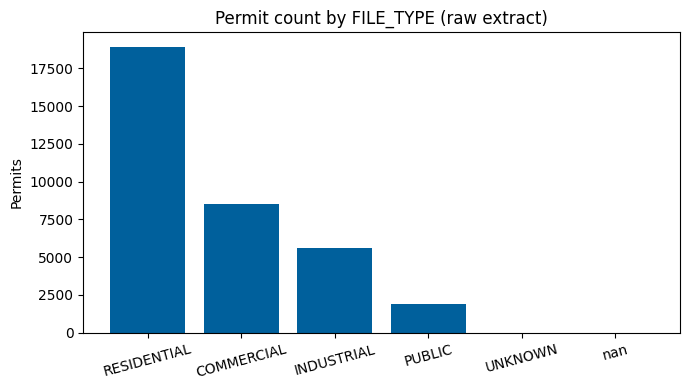

In [5]:
ft = (
    raw.groupby("FILE_TYPE", dropna=False)
    .agg(permits=("BP_NO", "count"), est_con_value=("EST_CON_VALUE", "sum"))
    .sort_values("permits", ascending=False)
)
ft["value_$B"] = (ft["est_con_value"] / 1e9).round(2)
ft["share_of_permits_%"] = (100 * ft["permits"] / ft["permits"].sum()).round(1)
display(ft[["permits", "share_of_permits_%", "value_$B"]])

fig, ax = plt.subplots(figsize=(7, 4))
order = ft.index.astype(str)
ax.bar(order, ft["permits"], color="#00609C")
ax.set_title("Permit count by FILE_TYPE (raw extract)")
ax.set_ylabel("Permits")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 6. I inspect SCOPE categories for non-residential rows

SCOPE drives how I classify construction activity later (new construction, expansion, reinvestment). Signs, tents, temporary structures, and demolitions are not growth in floorspace, so I plan to exclude them from the core set.


In [6]:
NONRES = {"COMMERCIAL", "INDUSTRIAL", "PUBLIC"}
nonres_preview = raw[raw["FILE_TYPE"].isin(NONRES)].copy()
scope_tbl = (
    nonres_preview.groupby("SCOPE", dropna=False)
    .agg(permits=("BP_NO", "count"), value=("EST_CON_VALUE", "sum"))
    .sort_values("permits", ascending=False)
)
scope_tbl["value_$M"] = (scope_tbl["value"] / 1e6).round(1)
display(scope_tbl[["permits", "value_$M"]].head(20))


,permits,value_$M
SCOPE,,
ALTERATION TO EXISTING BLDG,7293,3351.4
OTHER,3736,195.6
FASCIA SIGN,2236,29.5
PYLON SIGN,444,9.8
NEW BUILDING,384,3148.1
REVISIONS,354,36.3
TENTS/AIR SUPPORT STRUC,306,3.1
ELECTROMAG LOCK DEVICE,245,8.3
ADDITION AND ALTERATION,228,427.6


## 7. I define cleaning rules, then apply them step by step

I clean in Python (not Power Query) so every exclusion is auditable here.

1. Keep FILE_TYPE in Commercial, Industrial, Public.  
2. Drop STATUS = REVOKED.  
3. Drop non-growth SCOPEs: signs, tents/air support, electromagnetic locks, temporary structures, demolition.  
4. Drop remaining DEMO = Y rows.  
5. Deduplicate likely same-project reissues: same address, both values ≥ $1M, values within 10%, issue dates within 730 days – I keep the later permit and drop the earlier one.  
6. Classify WORK_KIND for Power BI using source terminology: New building, Addition, Alteration, Other work.  
7. Add ward labels (`Ward 1` … `Ward 11`) for charts.  
8. Add helper columns for years and permit timing (no KPI metrics – those are DAX in Power BI).  
9. Flag 2026 as incomplete YTD (`YEAR_COMPLETE = False`, label `2026*`).


In [7]:
EXCLUDED_SCOPES = {
    "FASCIA SIGN", "PYLON SIGN", "MULTIPLE SIGNS", "BILLBOARD SIGN",
    "DIRECTIONAL SIGN", "DIRECTORY SIGN", "TENTS/AIR SUPPORT STRUC",
    "ELECTROMAG LOCK DEVICE", "TEMPORARY STRUCTURE", "DEMOLITION",
}

def classify_work_kind(scope: str) -> str:
    # Keep original SCOPE terminology in the cleaned file (not briefing aliases).
    if scope == "NEW BUILDING":
        return "New building"
    if scope in {"ADDITION TO EXISTING BLDG", "ADDITION AND ALTERATION", "MEZZANINE"}:
        return "Addition"
    if scope == "ALTERATION TO EXISTING BLDG":
        return "Alteration"
    return "Other work"

audit = []

work = raw[raw["FILE_TYPE"].isin(NONRES)].copy()
audit.append({"step": "Start – non-residential FILE_TYPE", "rows": len(work),
              "value_$M": round(work["EST_CON_VALUE"].sum() / 1e6, 1)})

n_revoked = int((work["STATUS"] == "REVOKED").sum())
work = work[work["STATUS"] != "REVOKED"].copy()
audit.append({"step": f"Remove REVOKED ({n_revoked})", "rows": len(work),
              "value_$M": round(work["EST_CON_VALUE"].sum() / 1e6, 1)})

n_excl = int(work["SCOPE"].isin(EXCLUDED_SCOPES).sum())
work = work[~work["SCOPE"].isin(EXCLUDED_SCOPES)].copy()
audit.append({"step": f"Remove signs/tents/temp/demolition scopes ({n_excl})", "rows": len(work),
              "value_$M": round(work["EST_CON_VALUE"].sum() / 1e6, 1)})

n_demo = int((work["DEMO"] == "Y").sum())
work = work[work["DEMO"] != "Y"].copy()
audit.append({"step": f"Remove DEMO = Y ({n_demo})", "rows": len(work),
              "value_$M": round(work["EST_CON_VALUE"].sum() / 1e6, 1)})

work["ADDRESS_KEY"] = work["ADDRESS"].fillna("").str.strip().str.upper()
work = work.sort_values(["ADDRESS_KEY", "ISSUE_DATE"])
drop_idx = set()
for addr, grp in work.groupby("ADDRESS_KEY", sort=False):
    if not addr:
        continue
    idxs = list(grp.index)
    for a in range(len(idxs)):
        for b in range(a + 1, len(idxs)):
            i, j = idxs[a], idxs[b]
            vi, vj = work.at[i, "EST_CON_VALUE"], work.at[j, "EST_CON_VALUE"]
            if vi < 1_000_000 or vj < 1_000_000:
                continue
            if min(vi, vj) / max(vi, vj) < 0.90:
                continue
            if abs((work.at[i, "ISSUE_DATE"] - work.at[j, "ISSUE_DATE"]).days) > 730:
                continue
            earlier = i if work.at[i, "ISSUE_DATE"] <= work.at[j, "ISSUE_DATE"] else j
            drop_idx.add(earlier)

dedup_value = float(work.loc[list(drop_idx), "EST_CON_VALUE"].sum()) if drop_idx else 0.0
dropped_objectids = (
    work.loc[list(drop_idx), "OBJECTID"].astype(int).tolist() if drop_idx else []
)
core = work.drop(index=list(drop_idx)).copy()
audit.append({
    "step": f"Deduplicate likely reissues ({len(drop_idx)}, ${dedup_value/1e6:,.0f}M removed)",
    "rows": len(core),
    "value_$M": round(core["EST_CON_VALUE"].sum() / 1e6, 1),
})

display(pd.DataFrame(audit))
print(f"Core analysis set: {len(core):,} permits, ${core['EST_CON_VALUE'].sum()/1e9:.2f} billion.")
print(f"Likely large reissues dropped (OBJECTID count): {len(dropped_objectids)}")


,step,rows,value_$M
0,Start – non-residential FILE_TYPE,16094,7574.1
1,Remove REVOKED (7),16087,7574.0
2,Remove signs/tents/temp/demolition scopes (3645),12442,7491.6
3,Remove DEMO = Y (0),12442,7491.6
4,"Deduplicate likely reissues (50, $332M removed)",12392,7159.4


Core analysis set: 12,392 permits, $7.16 billion.
Likely large reissues dropped (OBJECTID count): 50


## 8. I enrich columns for Power BI (helpers only)

I add labels and timing fields Power BI can slice on. I do **not** pre-calculate dashboard KPIs here.


In [8]:
core = core.copy()
core["WORK_KIND"] = core["SCOPE"].map(classify_work_kind)
core["FILE_TYPE_LABEL"] = core["FILE_TYPE"].str.title()
core["ISSUE_YEAR"] = core["ISSUE_DATE"].dt.year.astype("Int64")
core["YEAR_COMPLETE"] = core["ISSUE_YEAR"] != 2026
core["ISSUE_YEAR_LABEL"] = core["ISSUE_YEAR"].map(
    lambda y: "2026*" if y == 2026 else (str(int(y)) if pd.notna(y) else None)
)
core["YTD_NOTE"] = np.where(
    core["ISSUE_YEAR"] == 2026,
    "YTD through 29 Sep 2026",
    "Full calendar year",
)
# Ward labels with community names (City of Mississauga council ward descriptions)
WARD_NAMES = {
    1: "Lakeview / Port Credit",
    2: "Clarkson / Lorne Park",
    3: "Rathwood / Applewood",
    4: "City Centre / Hurontario",
    5: "Malton / Northeast",
    6: "Erindale / Mavis",
    7: "Cooksville / Fairview",
    8: "Erin Mills",
    9: "Meadowvale",
    10: "Lisgar / Churchill Meadows",
    11: "Streetsville / Meadowvale Village",
}
core["WARD"] = pd.to_numeric(core["WARD"], errors="coerce").astype("Int64")

def ward_label(w):
    if pd.isna(w):
        return "Unknown ward"
    w = int(w)
    place = WARD_NAMES.get(w)
    return f"Ward {w} – {place}" if place else f"Ward {w}"

core["WARD_LABEL"] = core["WARD"].map(ward_label)
core["VALUE_M"] = core["EST_CON_VALUE"] / 1e6
core["DAYS_TO_ISSUE"] = (core["ISSUE_DATE"] - core["APPLICATION_DATE"]).dt.days
core["PERMIT_TIME_VALID"] = core["DAYS_TO_ISSUE"].between(0, 1095)
core["IS_OPEN"] = core["STATUS"] == "ISSUED PERMIT"
core["ACTIVITY"] = core["WORK_KIND"]

display(core[["FILE_TYPE_LABEL", "WORK_KIND", "WARD", "WARD_LABEL", "ISSUE_YEAR_LABEL"]].head(8))
print("WORK_KIND mix:")
display(core["WORK_KIND"].value_counts().to_frame("permits"))
print("Ward labels:")
display(
    core.groupby(["WARD", "WARD_LABEL"], as_index=False)
    .size()
    .rename(columns={"size": "permits"})
    .sort_values("WARD")
)


,FILE_TYPE_LABEL,WORK_KIND,WARD,WARD_LABEL,ISSUE_YEAR_LABEL
104,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2018
1359,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2018
2200,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2018
2454,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2018
2669,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2018
3196,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2018
3283,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2018
4212,Commercial,Alteration,4,Ward 4 – City Centre / Hurontario,2019


WORK_KIND mix:


,permits
Alteration,7253
Other work,4413
New building,376
Addition,350


Ward labels:


,WARD,WARD_LABEL,permits
0,1,Ward 1 – Lakeview / Port Credit,1064
1,2,Ward 2 – Clarkson / Lorne Park,653
2,3,Ward 3 – Rathwood / Applewood,571
3,4,Ward 4 – City Centre / Hurontario,877
4,5,Ward 5 – Malton / Northeast,4586
5,6,Ward 6 – Erindale / Mavis,492
6,7,Ward 7 – Cooksville / Fairview,673
7,8,Ward 8 – Erin Mills,1404
8,9,Ward 9 – Meadowvale,1092
9,10,Ward 10 – Lisgar / Churchill Meadows,124


## 9. I sanity-check the cleaned set with tables and charts

Full-year totals for 2018–2025, and 2026* as YTD. Orange marks the incomplete year so I never mistake it for a full-year comparable.


,permits,value_$M
FILE_TYPE_LABEL,,
Industrial,4827,3207.6
Commercial,6062,2555.9
Public,1503,1395.9


,ISSUE_YEAR,ISSUE_YEAR_LABEL,YEAR_COMPLETE,permits,value_$M
0,2018,2018,True,1533,833.8
1,2019,2019,True,1681,677.7
2,2020,2020,True,1339,656.8
3,2021,2021,True,1436,639.9
4,2022,2022,True,1426,808.7
5,2023,2023,True,1410,765.8
6,2024,2024,True,1291,1160.9
7,2025,2025,True,1320,873.7
8,2026,2026*,False,956,742.1


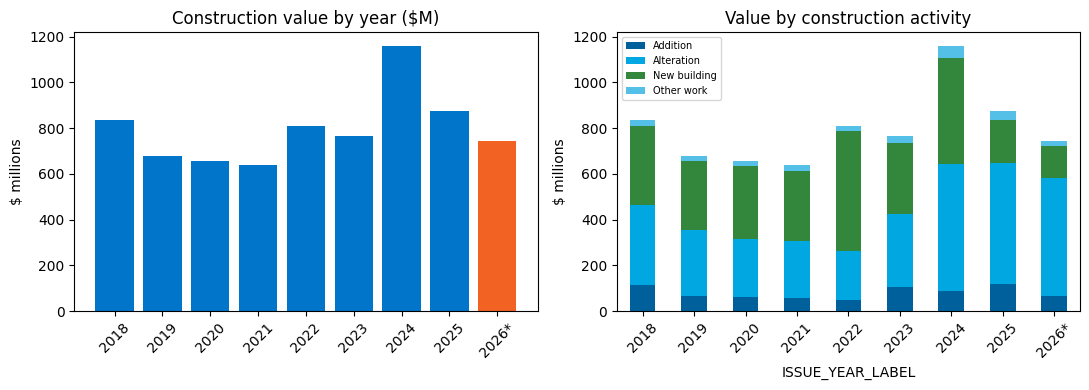

* 2026 is YTD through 29 September 2026, not a full calendar year.


In [9]:
by_type = (
    core.groupby("FILE_TYPE_LABEL")
    .agg(permits=("BP_NO", "count"), value_M=("VALUE_M", "sum"))
    .round(1)
    .sort_values("value_M", ascending=False)
)
by_type = by_type.rename(columns={"value_M": "value_$M"})
display(by_type)

by_year = (
    core.groupby(["ISSUE_YEAR", "ISSUE_YEAR_LABEL", "YEAR_COMPLETE"], as_index=False)
    .agg(permits=("BP_NO", "count"), value_M=("VALUE_M", "sum"))
    .sort_values("ISSUE_YEAR")
)
by_year["value_M"] = by_year["value_M"].round(1)
by_year = by_year.rename(columns={"value_M": "value_$M"})
display(by_year)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#0075C9" if c else "#F16223" for c in by_year["YEAR_COMPLETE"]]
axes[0].bar(by_year["ISSUE_YEAR_LABEL"], by_year["value_$M"], color=colors)
axes[0].set_title("Construction value by year ($M)")
axes[0].set_ylabel("$ millions")
axes[0].tick_params(axis="x", rotation=45)

wk = (
    core.groupby(["ISSUE_YEAR_LABEL", "WORK_KIND"], as_index=False)["VALUE_M"]
    .sum()
)
pivot = wk.pivot(index="ISSUE_YEAR_LABEL", columns="WORK_KIND", values="VALUE_M").fillna(0)
# keep year order
order = by_year["ISSUE_YEAR_LABEL"].tolist()
pivot = pivot.reindex(order)
pivot.plot(kind="bar", stacked=True, ax=axes[1],
           color=["#00609C", "#00A7E1", "#32873C", "#54C0E8"])
axes[1].set_title("Value by construction activity")
axes[1].set_ylabel("$ millions")
axes[1].legend(fontsize=7, loc="upper left")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print("* 2026 is YTD through 29 September 2026, not a full calendar year.")


## 10. I check permit timing quality

Days from application to issue can be negative (data entry) or extremely long. For Power BI medians I flag `PERMIT_TIME_VALID` when days are between 0 and 1,095 (about three years).


,metric,count
0,Rows with DAYS_TO_ISSUE calculated,12392
1,Negative days,0
2,Days > 1095,71
3,Valid for median (0–1095),12321


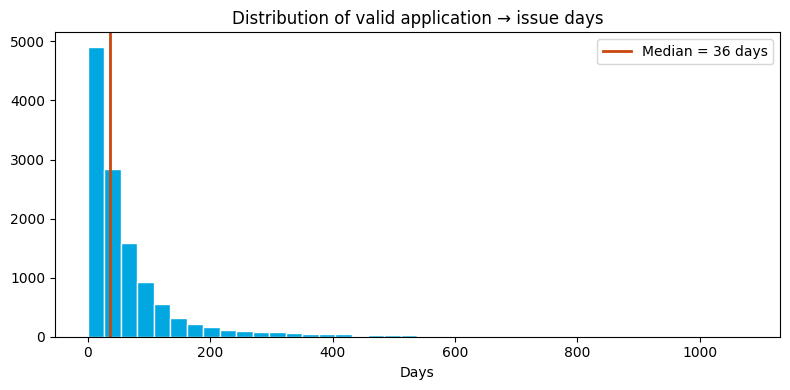

In [10]:
timing = pd.DataFrame({
    "metric": [
        "Rows with DAYS_TO_ISSUE calculated",
        "Negative days",
        "Days > 1095",
        "Valid for median (0–1095)",
    ],
    "count": [
        int(core["DAYS_TO_ISSUE"].notna().sum()),
        int((core["DAYS_TO_ISSUE"] < 0).sum()),
        int((core["DAYS_TO_ISSUE"] > 1095).sum()),
        int(core["PERMIT_TIME_VALID"].sum()),
    ],
})
display(timing)

valid = core.loc[core["PERMIT_TIME_VALID"], "DAYS_TO_ISSUE"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(valid, bins=40, color="#00A7E1", edgecolor="white")
ax.axvline(valid.median(), color="#C9470D", linewidth=2, label=f"Median = {valid.median():.0f} days")
ax.set_title("Distribution of valid application → issue days")
ax.set_xlabel("Days")
ax.legend()
plt.tight_layout()
plt.show()


## 11. I note geography caveats

Lat/long are present for mapping in Power BI. Postal codes are useful for ward and area views, with one known quirk: some rows use a placeholder-style code that should not be treated as a precise neighbourhood.


In [11]:
geo = pd.DataFrame({
    "check": [
        "LATITUDE present",
        "LONGITUDE present",
        "POSTAL_CODE missing",
        "POSTAL_CODE starts with A1A (placeholder risk)",
        "Distinct wards",
    ],
    "value": [
        int(core["LATITUDE"].notna().sum()),
        int(core["LONGITUDE"].notna().sum()),
        int(core["POSTAL_CODE"].isna().sum()),
        int(core["POSTAL_CODE"].fillna("").str.upper().str.startswith("A1A").sum()),
        int(core["WARD"].nunique()),
    ],
})
display(geo)
ward_tbl = (
    core.groupby("WARD_LABEL", as_index=False)
    .agg(permits=("BP_NO", "count"), value_M=("VALUE_M", "sum"))
)
ward_tbl["value_M"] = ward_tbl["value_M"].round(1)
ward_tbl = ward_tbl.rename(columns={"value_M": "value_$M"}).sort_values(
    "value_$M", ascending=False
)
display(ward_tbl.head(12))


,check,value
0,LATITUDE present,12392
1,LONGITUDE present,12392
2,POSTAL_CODE missing,6
3,POSTAL_CODE starts with A1A (placeholder risk),816
4,Distinct wards,11


,WARD_LABEL,permits,value_$M
6,Ward 5 – Malton / Northeast,4586,2457.7
3,Ward 2 – Clarkson / Lorne Park,653,941.4
9,Ward 8 – Erin Mills,1404,776.8
10,Ward 9 – Meadowvale,1092,693.2
2,Ward 11 – Streetsville / Meadowvale Village,856,589.5
5,Ward 4 – City Centre / Hurontario,877,385.8
0,Ward 1 – Lakeview / Port Credit,1064,384.6
7,Ward 6 – Erindale / Mavis,492,299.2
8,Ward 7 – Cooksville / Fairview,673,281.9
4,Ward 3 – Rathwood / Applewood,571,281.5


## 12. I export the cleaned CSV for Power BI

I write a Power BI–ready fact table with cleaned rows and helper columns only. All KPI math stays for DAX.


In [12]:
export_cols = [
    "OBJECTID", "BP_NO", "STATUS", "ADDRESS", "DESCRIPTION", "SCOPE",
    "FILE_TYPE", "FILE_TYPE_LABEL", "BLDG_TYPE", "EST_CON_VALUE", "VALUE_M",
    "DEMO", "POSTAL_CODE", "WARD", "WARD_LABEL", "ZAREA",
    "LATITUDE", "LONGITUDE", "x", "y",
    "APPLICATION_DATE", "ISSUE_DATE", "COMPLETE_DATE",
    "ISSUE_YEAR", "ISSUE_YEAR_LABEL", "YEAR_COMPLETE", "YTD_NOTE",
    "WORK_KIND", "ACTIVITY", "DAYS_TO_ISSUE", "PERMIT_TIME_VALID", "IS_OPEN",
]

clean = core[export_cols].sort_values(["ISSUE_DATE", "BP_NO"]).reset_index(drop=True)
out_path = OUT_DIR / "Fact_Permits_Clean.csv"
clean.to_csv(out_path, index=False)

# Timing outliers (> 3 years / 1,095 days) for Power BI table
outliers = clean.loc[clean["DAYS_TO_ISSUE"] > 1095, [
    "ADDRESS", "APPLICATION_DATE", "ISSUE_DATE", "DAYS_TO_ISSUE",
    "EST_CON_VALUE", "DESCRIPTION", "BP_NO", "FILE_TYPE_LABEL", "WORK_KIND", "WARD_LABEL",
]].sort_values("DAYS_TO_ISSUE", ascending=False).reset_index(drop=True)
outliers = outliers.rename(columns={"DAYS_TO_ISSUE": "DAYS_APP_TO_ISSUE"})
outliers_path = OUT_DIR / "Fact_Timing_Outliers.csv"
outliers.to_csv(outliers_path, index=False)

# Dropped likely large reissues in the SAME column layout as the original download CSV
reissues = raw[raw["OBJECTID"].isin(dropped_objectids)].copy()
reissues = reissues.sort_values(["ADDRESS", "ISSUE_DATE"]).reset_index(drop=True)
reissues_path = OUT_DIR / "Deduplicated_Large_Reissues.csv"
reissues.to_csv(reissues_path, index=False)

summary = pd.DataFrame([
    {"item": "Source", "detail": "Issued Building Permits CSV (Mississauga Open Data)"},
    {"item": "Raw rows", "detail": f"{len(raw):,}"},
    {"item": "Core non-residential rows", "detail": f"{len(clean):,}"},
    {"item": "Core construction value", "detail": f"${clean['EST_CON_VALUE'].sum()/1e9:.2f}B"},
    {"item": "Issue date window", "detail": f"{clean['ISSUE_DATE'].min().date()} to {clean['ISSUE_DATE'].max().date()}"},
    {"item": "2026 treatment", "detail": "Labelled 2026* – YTD through 29 Sep 2026"},
    {"item": "Full years", "detail": "2018–2025 kept as full calendar years"},
    {"item": "Timing outliers >1095 days", "detail": f"{len(outliers):,}"},
    {"item": "Likely large reissues dropped", "detail": f"{len(reissues):,}"},
])
print("Wrote:", out_path)
print("Wrote:", outliers_path, f"({len(outliers)} rows)")
print("Wrote:", reissues_path, f"({len(reissues)} rows)")
display(summary)
display(outliers.head(5))
display(reissues.head(3))


Wrote: C:\Users\princ\OneDrive\Documents\Other\COM-Assignment\Final_assignment\output\Fact_Permits_Clean.csv
Wrote: C:\Users\princ\OneDrive\Documents\Other\COM-Assignment\Final_assignment\output\Fact_Timing_Outliers.csv (71 rows)
Wrote: C:\Users\princ\OneDrive\Documents\Other\COM-Assignment\Final_assignment\output\Deduplicated_Large_Reissues.csv (50 rows)


,item,detail
0,Source,Issued Building Permits CSV (Mississauga Open ...
1,Raw rows,"35,042"
2,Core non-residential rows,"12,392"
3,Core construction value,$7.16B
4,Issue date window,2018-01-02 to 2026-09-29
5,2026 treatment,Labelled 2026* – YTD through 29 Sep 2026
6,Full years,2018–2025 kept as full calendar years
7,Timing outliers >1095 days,71
8,Likely large reissues dropped,50


,ADDRESS,APPLICATION_DATE,ISSUE_DATE,DAYS_APP_TO_ISSUE,EST_CON_VALUE,DESCRIPTION,BP_NO,FILE_TYPE_LABEL,WORK_KIND,WARD_LABEL
0,2555 HENSALL ST,1998-09-25,2024-01-09,9237,18000.0,(3) SPRAY- BOOTHS,BP 3ALT 98-11525,Industrial,Other work,Ward 7 – Cooksville / Fairview
1,2405 DREW RD,1996-11-14,2019-12-05,8421,40000.0,INTERIOR ALTERATIONS - DEETAG LTD,BP 3ALT 96-9345,Industrial,Alteration,Ward 5 – Malton / Northeast
2,5900 FALBOURNE ST,2003-05-05,2025-01-15,7926,250000.0,ALTERATIONS - RELOCATE DEMISING WALL & ALTERAT...,BP 3ALT 3-8401,Industrial,Alteration,Ward 5 – Malton / Northeast
3,640 EGLINTON AVE W,1998-02-23,2018-07-05,7437,24000.0,INTERIOR ALTERATIONS,BP 3ALT 98-7542,Commercial,Alteration,Ward 4 – City Centre / Hurontario
4,6075 MAVIS RD,2006-06-20,2026-03-20,7213,10000.0,(1) ROOFTOP UNIT,BP 3ALT 6-1582,Commercial,Other work,Ward 5 – Malton / Northeast


,OBJECTID,BP_NO,STATUS,ADDRESS,UNIT_NO,DESCRIPTION,SCOPE,FILE_TYPE,BLDG_TYPE,APP_DETAIL,APPL_AREA,STOREYS,EST_CON_VALUE,RES_UNITS,DEMO,POSTAL_CODE,BLDG_NO,WARD,ZAREA,LATITUDE,LONGITUDE,APPLICATION_DATE,ISSUE_DATE,COMPLETE_DATE,x,y
0,32191,BP 3ALT 25-10538,COMPLETED -ALL INSP SIGNED OFF,1 CITY CENTRE DR,1400,INTERIOR ALTERATIONS - GFT CANADA INC,ALTERATION TO EXISTING BLDG,COMMERCIAL,COMMERCIAL OFFICE - MULTI-USER,NaN,1534.0,NaN,3508258.0,NaN,N,L5B 1M2,NaN,4,29,43.596233,-79.640460,2025-10-28,2025-12-18,2026-09-03,-8.865535e+06,5.403170e+06
1,12351,BP 3ALT 21-5295,COMPLETED -ALL INSP SIGNED OFF,100 CITY CENTRE DR,2-709 and 2-710,INTERIOR ALTERATIONS - COMBINING UNIT 2-709 & ...,ALTERATION TO EXISTING BLDG,COMMERCIAL,COMMERCIAL RETAIL - MULTI-USER,NaN,NaN,NaN,1300000.0,NaN,N,L5B 2C9,NaN,4,29,43.592740,-79.642654,2021-02-26,2021-04-22,2022-02-28,-8.865780e+06,5.402633e+06
2,15205,BP 3ALT 21-7861,ISSUED PERMIT,100 CITY CENTRE DR,NaN,INTERIOR ALTERATIONS - INSTALLED NEW ESCALATOR...,ALTERATION TO EXISTING BLDG,COMMERCIAL,COMMERCIAL RETAIL - MULTI-USER,NaN,NaN,NaN,1367000.0,NaN,N,L5B 2C9,NaN,4,29,43.592740,-79.642654,2021-08-13,2022-01-07,NaT,-8.865780e+06,5.402633e+06


## 13. Cleaning measures – what I changed and why

| Step | What I did | Why |
| --- | --- | --- |
| Non-residential filter | Kept Commercial, Industrial, Public | Matches the growth question for Invest Mississauga |
| Revoked | Removed REVOKED status | Not active issued activity |
| Non-growth scopes | Removed signs, tents, locks, temporary, demolition | Not floorspace growth or reinvestment of buildings |
| DEMO flag | Removed DEMO = Y | Avoid counting teardown as growth |
| Deduplication | Dropped earlier of near-duplicate large permits at same address | Reduces double-counting of one project |
| WORK_KIND | Mapped SCOPE → New building / Addition / Alteration / Other work | Supports Construction Activity page in Power BI (briefing may say New Construction / Expansion / Reinvestment) |
| Ward labels | Built `WARD_LABEL` as Ward 1–11 from `WARD` | Readable ward charts and filters |
| Year labels | Full years 2018–2025; `2026*` + `YEAR_COMPLETE=False` | Honest comparison without cutting complete years to YTD |
| Permit time flag | `PERMIT_TIME_VALID` for days in 0–1095 | Stable medians without deleting rows |

**Next step.** Open `output/Fact_Permits_Clean.csv` and `output/Fact_Timing_Outliers.csv` in the Power BI project.
